# Qoro × PushQuantum Hackathon — 03 · PCE encodings and objectives (QOBLIB 06)

A copy of notebook 01 with one addition: in section 1.5, PCE is run on several instances
(`SELECTED_INSTANCES`, read from `instances/`) with every combination of encoding
(`PolyEncoding`, `DenseEncoding`) and objective (`SoftObjective`, `CVaRObjective`), and the
qubit counts and polished scores are plotted. Everything else is as in notebook 01.

**Takeaway:** `DenseEncoding` needs fewer qubits and reaches lower objectives; the choice of
objective matters little.

**Before you start,** work through notebook 00 (setup and QUBO 101) and notebook 01.

---
## 0 · Setup

Run these cells first. Notebook 00 (Part 0) explains them: your API key and the install. The helper file
`qoblib_tools.py` is downloaded for you.

In [1]:
# Setup, explained in notebook 00 (Part 0). If this cell installs Divi, restart the session
# (Runtime → Restart session) and run the notebook from the top.
import os
from importlib.metadata import PackageNotFoundError, version

try:
    divi_version = version("qoro-divi")
except PackageNotFoundError:
    divi_version = None
if divi_version != "0.16.2":
    %pip install -q "qoro-divi[qubo-decompose,jupyter]==0.16.2"
    print("Installed Divi 0.16.2: restart the session and run from the top.")

try:  # Google Colab: copy the secret QORO_API_KEY into the environment
    from google.colab import userdata
    os.environ["QORO_API_KEY"] = userdata.get("QORO_API_KEY")
except ImportError:
    pass  # not in Colab: Divi reads .env or the environment by itself
except Exception as err:  # no secret yet, or notebook access switched off
    print(f"No QORO_API_KEY in Colab Secrets yet ({type(err).__name__}): see notebook 00, section 0.1.")

In [2]:
# The helper file qoblib_tools.py (instance loaders and official scorers) is downloaded from the
# hackathon repository if it is not next to this notebook yet.
import urllib.request

if not os.path.exists("qoblib_tools.py"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/QoroQuantum/pushquantum-hackathon-2026/main/qoblib_tools.py", "qoblib_tools.py")
import qoblib_tools as qt

missing = [name for name in [
    "PortfolioModel", "PortfolioQUBO", "load_portfolio_instance", "read_portfolio_solution",
    "fetch_portfolio_reference",
] if not hasattr(qt, name)]
if missing:
    raise ImportError(
        f"{os.path.relpath(qt.__file__)} is an old copy (no {', '.join(missing)}). Delete it, restart the "
        "session and run from the top: the current version is downloaded."
    )
print("qoblib_tools loaded from", os.path.relpath(qt.__file__))

qoblib_tools loaded from qoblib_tools.py


In [3]:
import time
import warnings

warnings.filterwarnings("ignore", category=SyntaxWarning)  # noisy docstrings in some dependencies
warnings.filterwarnings("ignore", message='install "ipywidgets" for Jupyter support')


import dimod
import hybrid
import requests
from dwave.samplers import SimulatedAnnealingSampler
from IPython.display import display

from divi.backends import JobConfig, MaestroConfig, MaestroSimulator, QoroService
from divi.backends.characterization import characterize_and_validate
from divi.qprog.algorithms import CVaRObjective, DenseEncoding, PCE, PolyEncoding, SoftObjective
from divi.qprog.ensembles import BeamSearchStrategy, PartitioningProgramEnsemble
from divi.qprog.optimizers import MonteCarloOptimizer
from divi.qprog.problems import BinaryOptimizationProblem, CommunityDecomposer, QUBOPartitioningConfig

print("qoro-divi", version("qoro-divi"))

qoro-divi 0.16.2


In [16]:
USE_CLOUD = True            # False: local Maestro simulator · True: Qoro cloud (uses credits)
RUN_CHARACTERIZATION = False      # Characterization Service calls (cloud; cost scales with QUBO size)
SHOTS = 10_000
MC_POPULATION = 20          # Monte Carlo optimiser: circuits per iteration, sent to the backend as one batch
MC_ITERATIONS = 10          # Monte Carlo optimiser iterations

try:
    service = QoroService()  # reads QORO_API_KEY from .env or the environment
    balance = service.get_credit_balance()
    print("Connected to Qoro. Credit balance:", balance.get("balance", balance))
except (ValueError, requests.RequestException) as err:  # no key, a wrong key, or no connection
    service = None
    print(f"{err}\nNo working API key (notebook 00, section 0.1): cloud cells will be skipped.")
if USE_CLOUD and service is None:
    raise RuntimeError("USE_CLOUD = True needs a working API key: see notebook 00, section 0.1.")


def make_backend(shots: int = SHOTS, force_sampling: bool = False, maestro_config=None):
    # force_sampling=True: estimate everything from shots instead of exact expectation values
    if USE_CLOUD:
        return QoroService(
            job_config=JobConfig(
                shots=shots, simulator_cluster="qoro_maestro", force_sampling=force_sampling
            ),
            maestro_config=maestro_config,
        )
    return MaestroSimulator(shots=shots, force_sampling=force_sampling, maestro_config=maestro_config)


backend = make_backend()
print("Circuits run on:", type(backend).__name__)

Connected to Qoro. Credit balance: 890.00
Circuits run on: QoroService


**`solve_partitioned`** is the helper from notebook 00 (section 1.5), with one addition: an optional
`decomposer` argument, for when you want to choose the partitions yourself.

In [5]:
def solve_partitioned(bqm, routine="qaoa", cluster_size=12, n_layers=2, backend=backend, decomposer=None, **routine_kwargs):
    # Partition `bqm`, solve every part with `routine`, and return the ensemble.
    # routine: "qaoa" | "iterative_qaoa" | "pce" | "progressive_pce"
    problem = BinaryOptimizationProblem(
        bqm,
        decomposer=decomposer or CommunityDecomposer(
            QUBOPartitioningConfig(max_n_variables_per_cluster=cluster_size)
        ),
        composer=hybrid.SplatComposer(),
        local_search=True,
    )
    ensemble = PartitioningProgramEnsemble(
        problem=problem,
        quantum_routine=routine,
        n_layers=n_layers,
        optimizer=MonteCarloOptimizer(population_size=MC_POPULATION),
        max_iterations=MC_ITERATIONS,
        backend=backend,
        **routine_kwargs,
    )
    ensemble.run()
    return ensemble

---
## 1 · QOBLIB 06: multi-period portfolio optimisation

Over $T$ trading days, decide for each of $n$ stocks how many **units** to hold **long** and how many
**short** (0–3 each). One unit is worth 100 000 at day 0. The objective to minimise is

$$\underbrace{\lambda\,\text{risk}}_{\text{covariance}} \;-\; \text{returns} \;+\; \text{transaction costs} \;-\; \text{interest on idle cash} \;+\; \text{short fees} \;+\; \text{liquidation costs}$$

subject to two rules on every day:

* **Capital:** net position (long − short units) must lie between $C-15$ and $C = 10$.
* **Budget:** at most $B$ open units.

QOBLIB's model ([`bqp_u3_c10.zpl`](https://github.com/ZIB-AOPT/QOBLIB/tree/main/06-portfolio/models))
uses one binary variable per *(asset, unit copy, direction, day)* plus binary slack registers that
turn both rules into equalities. That gives about $6nT + 11T$ variables: **710 for 10 assets × 10 days**.

* **Instances:** `po_aXXX_tYY_sZZ` means XXX assets, YY days, data seed ZZ (or `orig`). Each is
  solved for 8 risk weights $\lambda \in \{0, 10^{-6}, \dots, 10^{-2}\}$ with $B$ = 4, 20, 50 or 100
  for 10, 50, 200 or 400 assets.
* **Score:** `PortfolioModel.score(positions)` computes QOBLIB's objective from your **unit counts
  only**. Use any QUBO you like, as long as you decode it to unit counts.

### 1.1 A tiny instance and the referee

In [6]:
inst = qt.load_portfolio_instance("po_a003_t02_orig")  # 3 assets × 2 days (downloaded once)
model = qt.PortfolioModel(inst, budget=3, lam="1e-5")

print("Value of one unit over time:")
for i, sym in enumerate(inst.symbols):
    print(f"  {sym:>5}: {[round(float(p)) for p in model.unit_prices[i]]}")

Value of one unit over time:
   AAPL: [100000, 99154]
   NVDA: [100000, 100008]
   MSFT: [100000, 100915]


First, check the referee against a published QOBLIB result. Then compute the exact optimum of the tiny
instance by dynamic programming. This only works for about 3 assets, but it gives a ground truth to test
your pipeline against.

In [7]:
ref_model = qt.PortfolioModel(qt.load_portfolio_instance("po_a010_t10_orig"), budget=4, lam="1e-4")
header, ref_positions = qt.read_portfolio_solution(
    qt.fetch_portfolio_reference("po_a010_t10_orig", budget=4, lam_tag="1e-4")
)
print("QOBLIB reference solution — published objective:", header["objective"])
print("                              our referee says:   ", ref_model.score(ref_positions))

best_positions, best_obj = model.brute_force()
print("\nTiny instance — exact optimum:", best_obj)
print("  positions {(day, symbol): (long, short)}:", best_positions)
print("  ", model.score(best_positions))

QOBLIB reference solution — published objective: -69482
                              our referee says:    objective=-69482 (feasible; risk=23416, return=-97869, transaction=5821, cash_interest=-880, short_cost=30, liquidation=0)

Tiny instance — exact optimum: -2505
  positions {(day, symbol): (long, short)}: {(0, 'AAPL'): (0, 1), (0, 'MSFT'): (2, 0)}
   objective=-2505 (feasible; risk=58, return=-2676, transaction=300, cash_interest=-190, short_cost=3, liquidation=0)


### 1.2 From model to QUBO

`PortfolioQUBO` builds QOBLIB's model as two binary quadratic models over the same variables:

* `objective`: the cost function.
* `penalty`: the two squared equality constraints, zero exactly on feasible bitstrings.

The solver sees `objective + W · penalty`, and **the penalty weight `W` is your most important knob.**
If `W` is too small, samples break the rules. If it's too large, the objective is drowned out and
quality suffers.

Keyword arguments let you change the encoding while keeping the same score. Fewer copies (`ub`) or
narrower slack registers mean fewer variables.

In [8]:
q = qt.PortfolioQUBO(model)
print(f"{q.n_vars} binary variables = {q.n_x} position bits + {q.n_vars - q.n_x} slack bits")

bits = q.encode(best_positions)  # positions → bits (unit copies + exact slack values)
print("objective energy of the optimum:", q.objective.energy(dict(enumerate(bits))),
      "| penalty:", q.penalty.energy(dict(enumerate(bits))))


def penalised(q: qt.PortfolioQUBO, weight: float, normalize: bool = False) -> dimod.BinaryQuadraticModel:
    # objective + weight·penalty as one BQM (optionally rescaled so |coefficients| ≤ 1).
    bqm = q.objective.copy()
    penalty = q.penalty.copy()
    penalty.scale(weight)
    bqm.update(penalty)
    if normalize:
        bqm.normalize()
    return bqm


def best_polished(model: qt.PortfolioModel, q: qt.PortfolioQUBO, samples, top: int = 10):
    # Decode the first `top` samples, repair + local-search each, return (positions, score) of the best.
    candidates = [model.local_search(q.decode(s)) for s in list(samples)[:top]]
    best = min(candidates, key=lambda p: model.score(p).objective)
    return best, model.score(best)

58 binary variables = 36 position bits + 22 slack bits
objective energy of the optimum: -2505.0 | penalty: 0.0


### 1.3 Characterize the portfolio QUBO and tune the penalty

Pass the objective and the penalty *separately*, using `BinaryOptimizationProblem(objective, penalty=…)`.
Divi then sends the cost/penalty split on its own, and the report gains a `penalty` section with the
weight thresholds and, for small enough problems, a recommended weight (`recommended_lambda`).

The `structure` section is worth reading too. It shows how well the QUBO splits into parts, which
helps you choose a partition size in 1.6.

Divi warns that the QUBO's constant offset isn't sent: the reported energies exclude it, and nothing else changes.

In [9]:
W = 1000.0  # starting guess

pf_report = None
if service is not None and RUN_CHARACTERIZATION:
    pf_report = characterize_and_validate(
        BinaryOptimizationProblem(q.objective, penalty=q.penalty, penalty_weight=W),
        reference_states=[q.bitstring(best_positions)],
        service=service,
    )
    display(pf_report)
    print("penalty section:   ", pf_report.penalty)
    print("structure section: ", pf_report.structure)
    if pf_report.recommended_lambda:
        W = float(pf_report.recommended_lambda)
else:
    print("Skipped: no API key, or RUN_CHARACTERIZATION is False.")
print("Using penalty weight W =", W)

Skipped: no API key, or RUN_CHARACTERIZATION is False.
Using penalty weight W = 1000.0


### 1.4 Classical baseline: simulated annealing → repair → local search

**Always know your classical bar.** `model.repair` makes a solution feasible by dropping the least
valuable units, and `model.local_search` then applies single-unit moves while they improve the
*official* score. Use both as post-processing on any sample, quantum or classical.

In [10]:
t0 = time.time()
sa = SimulatedAnnealingSampler().sample(penalised(q, W), num_reads=100, num_sweeps=1000, seed=1)
n_feasible = sum(model.score(q.decode(s)).feasible for s in sa.samples())
sa_positions, sa_score = best_polished(model, q, sa.samples())
print(f"SA: {n_feasible}/100 raw samples feasible; after repair + local search: {sa_score.objective} "
      f"({time.time() - t0:.1f}s) — optimum {best_obj}")

SA: 73/100 raw samples feasible; after repair + local search: -2505 (0.1s) — optimum -2505


### 1.5 Quantum route A: PCE on the whole QUBO

58 variables won't fit in one QAOA circuit on a laptop, but `PolyEncoding` needs only 11 qubits.

In [17]:
import json
from fractions import Fraction
from pathlib import Path

# Takeway: denseEncoding is better (fewer qubits and lower objective), the objective is not that important.

SELECTED_INSTANCES = [
    "po_a003_t02_orig", 
    "po_a004_t04_s02", 
    "po_a050_t10_orig", 
    "po_a050_t15_s02", 
    "po_a050_t15_s01", 
]
INSTANCES_DIR = Path("instances")
BUDGET_BY_ASSETS = json.loads((INSTANCES_DIR / "manifest.json").read_text())["budget_by_assets"]


def load_local_instance(name: str, instances_dir: Path = INSTANCES_DIR) -> qt.PortfolioInstance:
    base = instances_dir / name
    symbols, index, entries = [], {}, []
    for day, sym, price in qt._data_rows(base / "stock_prices.txt.gz"):
        if sym not in index:
            index[sym] = len(symbols)
            symbols.append(sym)
        entries.append((index[sym], int(day), Fraction(price)))
    n_periods = max(t for _, t, _ in entries) + 1
    prices = [[None] * n_periods for _ in symbols]
    for i, t, p in entries:
        prices[i][t] = p
    cov = {}
    for day, s1, s2, value in qt._data_rows(base / "covariance_matrices.txt.gz"):
        t = int(day)
        if s1 in index and s2 in index and t < n_periods:
            cov[index[s1], index[s2], t] = Fraction(value)
    return qt.PortfolioInstance(name, symbols, n_periods, prices, cov)


pce_results = []
cloud_backend = QoroService(
    job_config=JobConfig(shots=SHOTS, simulator_cluster="qoro_maestro")
)

for inst_name in SELECTED_INSTANCES:
    inst_data = load_local_instance(inst_name)
    inst_budget = BUDGET_BY_ASSETS[str(inst_data.n_assets)]
    inst_model = qt.PortfolioModel(inst_data, budget=inst_budget, lam="1e-5")
    inst_q = qt.PortfolioQUBO(inst_model)
    try:
        _, inst_best_obj = inst_model.brute_force()
    except ValueError:
        inst_best_obj = None
    pf_problem = BinaryOptimizationProblem(penalised(inst_q, W, normalize=True))

    for objective in [SoftObjective(alpha=2.0), CVaRObjective(fraction=0.9)]:  # , HardObjective()]:
        for encoding in [PolyEncoding(), DenseEncoding()]:  # , GrayEncoding(), UnaryEncoding()]:
            obj_name = type(objective).__name__
            enc_name = type(encoding).__name__
            mps_cfg = (
                MaestroConfig(simulation_type="MatrixProductState", max_bond_dimension=16)
                if isinstance(encoding, PolyEncoding) and inst_q.n_vars > 210
                else None
            )
            cloud_backend.job_config = JobConfig(
                shots=SHOTS,
                simulator_cluster="qoro_maestro",
                force_sampling=isinstance(objective, CVaRObjective),
            )
            cloud_backend.maestro_config = mps_cfg
            t0 = time.time()
            pce_pf = PCE(
                pf_problem,
                encoding=encoding,
                objective=objective,
                n_layers=3,
                optimizer=MonteCarloOptimizer(population_size=MC_POPULATION),
                max_iterations=MC_ITERATIONS,
                backend=cloud_backend,
                seed=1,
            )
            pce_pf.run()
            top = pce_pf.get_top_solutions(n=20, min_prob=0.0, sort_by="energy")
            raw_best = min(inst_model.score(inst_q.decode(s.bitstring)).objective for s in top)
            pce_positions, pce_score = best_polished(inst_model, inst_q, [s.bitstring for s in top])
            opt_str = inst_best_obj if inst_best_obj is not None else "N/A"
            print(
                f"[{inst_name} | {obj_name} | {enc_name}] "
                f"PCE: {inst_q.n_vars} variables on {pce_pf.n_qubits} qubits, {pce_pf.total_circuit_count} circuits, "
                f"{time.time() - t0:.1f}s"
            )
            print(
                f"  best raw sample: {raw_best} | after repair + local search: {pce_score.objective} (optimum {opt_str})"
            )
            pce_results.append({
                "instance": inst_name,
                "encoding": enc_name,
                "objective": obj_name,
                "combo": f"{enc_name} + {obj_name}",
                "n_qubits": pce_pf.n_qubits,
                "pce_score": pce_score.objective,
            })

[po_a003_t02_orig | SoftObjective | PolyEncoding] PCE: 58 variables on 11 qubits, 201 circuits, 43.3s
  best raw sample: -741 | after repair + local search: -2505 (optimum -2505)


[po_a003_t02_orig | SoftObjective | DenseEncoding] PCE: 58 variables on 6 qubits, 201 circuits, 46.5s
  best raw sample: -2096 | after repair + local search: -2444 (optimum -2505)


[po_a003_t02_orig | CVaRObjective | PolyEncoding] PCE: 58 variables on 11 qubits, 201 circuits, 44.4s
  best raw sample: -741 | after repair + local search: -2505 (optimum -2505)


[po_a003_t02_orig | CVaRObjective | DenseEncoding] PCE: 58 variables on 6 qubits, 201 circuits, 44.3s
  best raw sample: -2096 | after repair + local search: -2444 (optimum -2505)


[po_a004_t04_s02 | SoftObjective | PolyEncoding] PCE: 140 variables on 17 qubits, 201 circuits, 41.7s
  best raw sample: -16922 | after repair + local search: -34925 (optimum N/A)


[po_a004_t04_s02 | SoftObjective | DenseEncoding] PCE: 140 variables on 8 qubits, 201 circuits, 41.1s
  best raw sample: -10195 | after repair + local search: -37348 (optimum N/A)


[po_a004_t04_s02 | CVaRObjective | PolyEncoding] PCE: 140 variables on 17 qubits, 201 circuits, 97.1s
  best raw sample: -16095 | after repair + local search: -34925 (optimum N/A)


[po_a004_t04_s02 | CVaRObjective | DenseEncoding] PCE: 140 variables on 8 qubits, 201 circuits, 41.7s
  best raw sample: -17935 | after repair + local search: -36172 (optimum N/A)


[po_a050_t10_orig | SoftObjective | PolyEncoding] PCE: 3110 variables on 79 qubits, 201 circuits, 132.5s
  best raw sample: 47819 | after repair + local search: -430416 (optimum N/A)


[po_a050_t10_orig | SoftObjective | DenseEncoding] PCE: 3110 variables on 12 qubits, 201 circuits, 137.3s
  best raw sample: 22596 | after repair + local search: -430672 (optimum N/A)


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/divi/qprog/varia │
│ tional_quantum_algorithm.py:1579 in _optimize                                                    │
│                                                                                                  │
│   1576 │   │   try:                                                                              │
│   1577 │   │   │   with self._install_cancellation_handler():                                    │
│   1578 │   │   │   │   try:                                                                      │
│ ❱ 1579 │   │   │   │   │   self.optimize_result = self.optimizer.optimize(**optimize_kwargs)     │
│   1580 │   │   │   │   except StopIteration:                                                     │
│   1581 │   │   │   │   │   reason = self._stop_reason.value if self._stop_reason else "Stopped"  │
│   1582 │   │   │   │   │   self.optimize_result = OptimizeResult(                                │
│                                                                                                  │
│ /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/divi/qprog/optim │
│ izers/_monte_carlo.py:278 in optimize                                                            │
│                                                                                                  │
│   275 │   │                                                                                      │
│   276 │   │   for curr_iter in range(start_iter, end_iter):                                      │
│   277 │   │   │   # Evaluate the entire population once                                          │
│ ❱ 278 │   │   │   self._curr_losses = np.atleast_1d(cost_fn(self._curr_population)).astype(      │
│   279 │   │   │   │   np.float64                                                                 │
│   280 │   │   │   )                                                                              │
│   281 │   │   │   self._curr_evaluated_population = np.copy(self._curr_population)               │
│                                                                                                  │
│ /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/divi/qprog/varia │
│ tional_quantum_algorithm.py:1414 in cost_fn                                                      │
│                                                                                                  │
│   1411 │   │   │   │   )                                                                         │
│   1412 │   │   │   )                                                                             │
│   1413 │   │   │                                                                                 │
│ ❱ 1414 │   │   │   values_map = self._evaluate_cost_param_sets(                                  │
│   1415 │   │   │   │   np.atleast_2d(params),                                                    │
│   1416 │   │   │   │   shots=shots,                                                              │
│   1417 │   │   │   │   estimator_samples=estimator_samples,                                      │
│                                                                                                  │
│ /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/divi/qprog/algor │
│ ithms/_pce.py:628 in _evaluate_cost_param_sets                                                   │
│                                                                                                  │
│   625 │   │   │   │   │   "QiskitSimulator(force_sampling=True), or QoroService with "           │
│   626 │   │   │   │   │   "JobConfig(force_sampling=True)."                                      │
│   627 │   │   │   │   )                                    

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dty

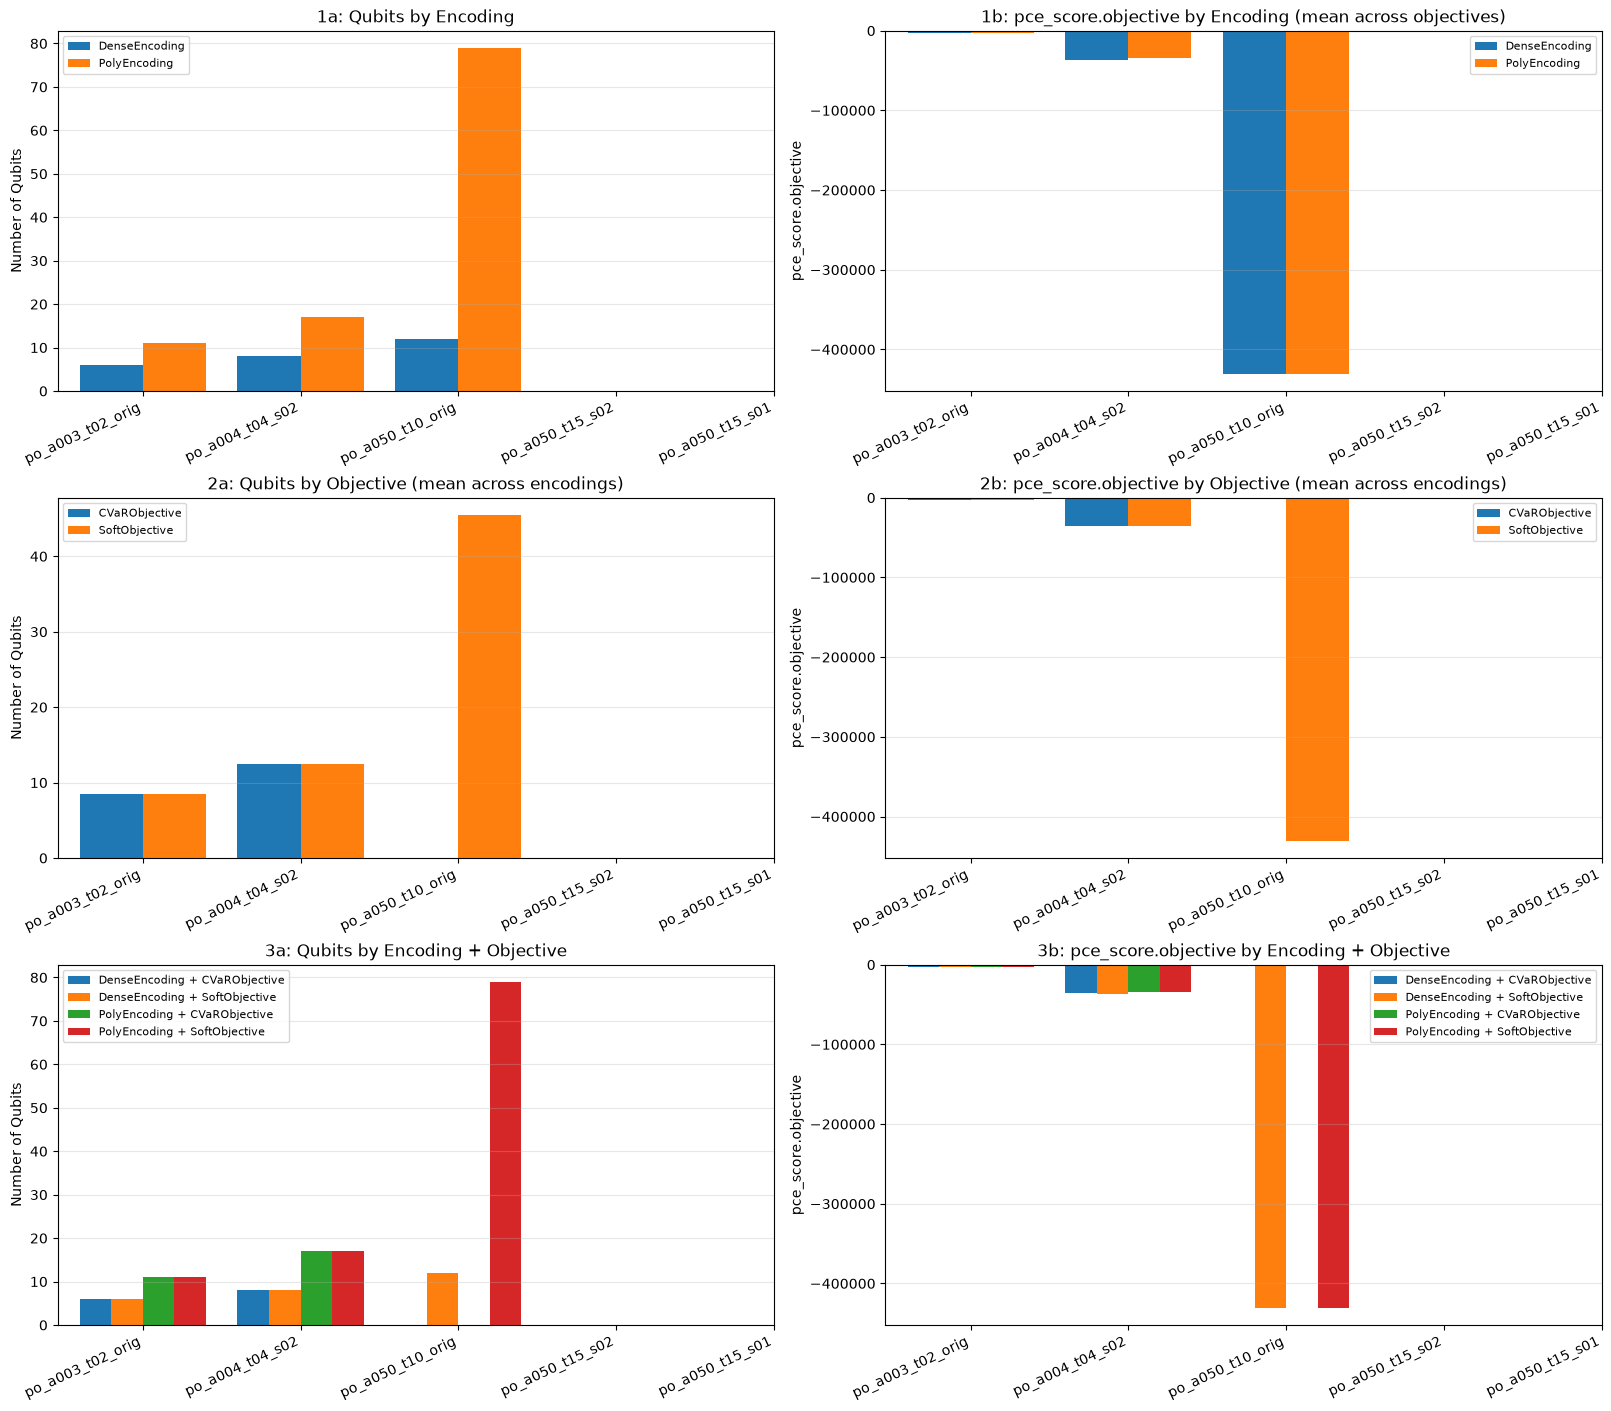

In [18]:
import matplotlib.pyplot as plt
import numpy as np

instances = SELECTED_INSTANCES
encodings = ["DenseEncoding", "PolyEncoding"]
objectives = ["CVaRObjective", "SoftObjective"]
combos = [f"{enc} + {obj}" for enc in encodings for obj in objectives]


def plot_grouped(ax, group_key, groups, metric, title, ylabel):
    x = np.arange(len(instances))
    width = 0.8 / len(groups)
    for idx, g in enumerate(groups):
        vals = [
            np.mean([r[metric] for r in pce_results if r["instance"] == inst and r[group_key] == g])
            for inst in instances
        ]
        offset = (idx - (len(groups) - 1) / 2) * width
        ax.bar(x + offset, vals, width, label=g)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(instances, rotation=25, ha="right")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)


fig, axes = plt.subplots(3, 2, figsize=(16, 14), constrained_layout=True)

plot_grouped(axes[0, 0], "encoding", encodings, "n_qubits", "1a: Qubits by Encoding", "Number of Qubits")
plot_grouped(axes[0, 1], "encoding", encodings, "pce_score", "1b: pce_score.objective by Encoding (mean across objectives)", "pce_score.objective")
plot_grouped(axes[1, 0], "objective", objectives, "n_qubits", "2a: Qubits by Objective (mean across encodings)", "Number of Qubits")
plot_grouped(axes[1, 1], "objective", objectives, "pce_score", "2b: pce_score.objective by Objective (mean across encodings)", "pce_score.objective")
plot_grouped(axes[2, 0], "combo", combos, "n_qubits", "3a: Qubits by Encoding + Objective", "Number of Qubits")
plot_grouped(axes[2, 1], "combo", combos, "pce_score", "3b: pce_score.objective by Encoding + Objective", "pce_score.objective")

plt.show()

### 1.6 Quantum route B: partition → QAOA → stitch → polish

In [ ]:
pf_bqm = penalised(q, W, normalize=True)
t0 = time.time()
ensemble = solve_partitioned(pf_bqm, "qaoa", cluster_size=10)
tops = ensemble.get_top_solutions(n=10, strategy=BeamSearchStrategy(beam_width=10, n_partition_candidates=5))
samples = [dict(zip(pf_bqm.variables, solution)) for solution, _ in tops]
part_positions, part_score = best_polished(model, q, samples)
print(f"Partitioned QAOA: {len(ensemble.programs)} sub-programs, {ensemble.total_circuit_count} circuits, "
      f"{time.time() - t0:.1f}s → {part_score.objective} after polishing (optimum {best_obj})")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Partitioned QAOA: 8 sub-programs, 4008 circuits, 1.9s → -2480 after polishing (optimum -2505)


### 1.7 Scale up to a leaderboard instance

`po_a010_t10_orig` with $B = 4$ and $\lambda = 10^{-4}$: 710 variables, best-known value **−69 482**.
With `USE_CLOUD = True` the 70 sub-programs of each run execute in parallel on Qoro's cloud.
Each run sends 70 × 501 ≈ 35 000 circuits (lower `MC_POPULATION` or `MC_ITERATIONS` to
spend fewer credits). Locally, each run takes under a minute, depending on your machine.

Results vary from run to run, so we try three seeds and keep the best. When you're hunting a record,
running many attempts and keeping the best is fair play.

In [ ]:
INSTANCE, BUDGET, LAM, BKV = "po_a010_t10_orig", 4, "1e-4", -69482
W_BIG = 100.0  # smaller weights let the objective steer the search; repair restores feasibility

big_model = qt.PortfolioModel(qt.load_portfolio_instance(INSTANCE), budget=BUDGET, lam=LAM)
big_q = qt.PortfolioQUBO(big_model)
print(f"{INSTANCE}, B={BUDGET}, λ={LAM}: {big_q.n_vars} QUBO variables")
print("Local search from an empty portfolio:", big_model.score(big_model.local_search({})).objective)

big_bqm = penalised(big_q, W_BIG, normalize=True)
runs = []
for seed in (1, 2, 3):
    t0 = time.time()
    big_ensemble = solve_partitioned(big_bqm, "qaoa", cluster_size=12, backend=make_backend(), seed=seed)
    big_tops = big_ensemble.get_top_solutions(
        n=10, strategy=BeamSearchStrategy(beam_width=10, n_partition_candidates=5)
    )
    big_samples = [dict(zip(big_bqm.variables, solution)) for solution, _ in big_tops]
    positions, score = best_polished(big_model, big_q, big_samples)
    runs.append((score.objective, positions))
    print(f"seed {seed}: {score.objective} ({len(big_ensemble.programs)} sub-programs, "
          f"{big_ensemble.total_circuit_count} circuits, {time.time() - t0:.0f}s)")

best_run, big_positions = min(runs, key=lambda r: r[0])
big_score = big_model.score(big_positions)
print(f"\nBest of {len(runs)} runs: {best_run} — BKV {BKV}, gap {(best_run - BKV) / abs(BKV):+.2%}")
print(big_score)

po_a010_t10_orig, B=4, λ=1e-4: 710 QUBO variables
Local search from an empty portfolio: -69372


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

... (28 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

seed 3: -69215 (70 sub-programs, 35070 circuits, 32s)

Best of 3 runs: -69215 — BKV -69482, gap +0.38%
objective=-69215 (feasible; risk=23400, return=-97784, transaction=5819, cash_interest=-880, short_cost=32, liquidation=198)


Write your solution in QOBLIB's canonical `.sol` format. This is the file you hand in.

In [ ]:
lam_tag = LAM.replace("-0", "-")
sol_path = f"{INSTANCE}_b{BUDGET:03d}_l{lam_tag}.sol"
result = big_model.write_solution(sol_path, big_positions, comment="Qoro x QOBLIB hackathon: partitioned QAOA + local search")
print(f"Wrote {sol_path}: {result}")
print(open(sol_path).read()[:400])

Wrote po_a010_t10_orig_b004_l1e-4.sol: objective=-69215 (feasible; risk=23400, return=-97784, transaction=5819, cash_interest=-880, short_cost=32, liquidation=198)
# Qoro x QOBLIB hackathon: partitioned QAOA + local search
instance po_a010_t10_orig
budget 4
lambda 0.0001
objective -69215
# period symbol long short
0 AAPL 0 1
0 GOOGL 3 0
1 META 1 0
1 TSLA 0 3
2 AVGO 1 0
2 META 2 0
2 NVDA 0 1
3 AVGO 0 1
3 GOOG 0 2
3 META 1 0
4 AMZN 1 0
4 META 2 0
4 TSLA 0 1
5 GOOG 1 0
5 META 0 1
5 TSLA 2 0
6 GOOG 1 0
6 MSFT 1 0
6 NVDA 0 1
6 TSLA 1 0
7 TSLA 0 1
7 WMT 3 0
8 AAPL


### 1.8 Targets and ideas

Best-known values from the [QOBLIB table](https://github.com/ZIB-AOPT/QOBLIB/blob/main/06-portfolio/solutions/README.md)
(check it for updates), with what this notebook's classical starter tools reach. "SA + LS" is
simulated annealing on the official QUBO (W = 100), followed by `local_search`.

| Instance | B | λ | Best known | Starter (SA + LS) | |
|---|---:|---:|---:|---:|---|
| `po_a010_t10_orig` | 4 | 1e-4 | −69 482 | −69 482 | matched: warm-up |
| `po_a010_t10_orig` | 4 | 5e-4 | −27 044 | −26 548 | gap 1.8 % |
| `po_a010_t10_s02`  | 4 | 1e-4 | −53 255 | −51 805 | gap 2.7 % |
| `po_a050_t10_orig` | 20 | 1e-3 | −206 239 | −197 953 | gap 4.0 % |
| `po_a010_t10_orig` | 4 | 1e-3 | −8 397 | −3 703 | gap 56 % |
| `po_a050_t10_orig` | 20 | 1e-2 | −37 107 | −1 000 (local search alone) | gap 97 % |
| `po_a200_*`, `po_a400_*` | 50 / 100 | any | *none published* | — | uncharted |

The large-λ instances are where risk matters. Profitable portfolios need *hedged* long/short pairs,
which is a strongly coupled, frustrated QUBO. Single-unit moves get stuck there.

**Ideas to try**
* **Penalties.** Sweep `W`, use the characterizer's recommendation, or replace equality + slack with
  *unbalanced penalisation* of the inequalities. Feasibility is scored, not your penalty.
* **Encoding.** Use fewer copies (`ub=2`), narrower slack registers (`count_slack_bits=3` covers
  B = 4), or integer (binary) encoding of unit counts instead of unary copies. The cash interest
  equals $-10\,(C - \text{net position})$, which is linear in your positions. Fold it into the
  objective and enforce the capital rule as an inequality (for example, unbalanced penalisation) to
  drop the cash slack bits.
* **Partitioning.** Day-by-day blocks are natural, because days only couple through rebalancing costs.
  Try other cluster sizes, `HierarchicalStrategy` aggregation, or `hybrid.EnergyImpactDecomposer`.
* **Use the report.** Substitute `report.fixed_values` to shrink the QUBO before solving, and read
  `report.structure` to pick partition sizes.
* **Warm starts.** Seed QAOA from the service's angles. Use the best classical solution as
  `reference_states`. Restrict the search to the neighbourhood of an incumbent.
* **Hybrid loops.** Fix most variables to the incumbent, re-solve a window of assets × days with
  QAOA/PCE, accept if the official score improves, and repeat (large-neighbourhood search).
* **Scale out.** With `USE_CLOUD = True`, sub-programs run in parallel. Use more shots, more layers,
  `quantum_routine="iterative_qaoa"` or `"progressive_pce"`.

---
## Handing in

Keep every `.sol` file you write, with the instance, its size and the method and settings that produced
it. **Handing in** at the end of notebook 00 says how to submit.